# 서울 따릉이 대여 수요 예측
### 수업에서 배운 내용으로 직접 만든 "최적 모델 자동 탐색" (AutoML 아이디어 구현)

- **데이터** : UCI Machine Learning Repository, *Seoul Bike Sharing Demand* (2017.12 ~ 2018.11, 시간 단위 8,760행)
- **목표** : 날씨·시간 조건으로 따릉이 대여량을 예측한다. 이때 **변수 조합 × 스케일링 방법 × 알고리즘·파라미터**를 `for`문으로 자동 탐색해 가장 좋은 모델을 찾는다.

**분석 질문**
- Q1. 따릉이는 언제 가장 많이 탈까? (시간대, 요일, 계절)
- Q2. 날씨 중 무엇이 대여량에 가장 큰 영향을 줄까?
- Q3. 이 변수들로 대여량을 얼마나 정확히 예측할 수 있을까? (교수님 기준: 회귀 R² 60% 이상 / 분류 정확도 80% 이상)

### 배운 내용 활용표

| 단계 | 사용한 것 | 출처 | 위치 |
|---|---|---|---|
| 불러오기·탐색 | `read_csv`, `shape`, `head`, `describe`, `isnull().sum()`, `value_counts` | 실습 | 2장 |
| 이상치 확인 | `np.percentile`로 IQR 상한·하한 | 특성공학 수업 | 2장 |
| 날짜 처리 | `pd.to_datetime`, `.dt` | 실습(슈퍼마켓 시간대별 매출) | 3장 |
| 범주형 변환 | `LabelEncoder`, `map` | 실습(타이타닉·라리가), 교재 6장 | 3장 |
| 파생변수 | `map(...).fillna(0)` | 실습(라리가) | 3장 |
| 시각화 | `groupby`, `unstack`, `boxplot`, `scatterplot`, `kdeplot` | 실습 | 4장 |
| 로그 정규화 | `np.log` | 실습 | 4장 |
| 구간 나누기(Binning) | `np.percentile` + 함수 + `map` | 교재 11장, 실습 | 5장 |
| 데이터 분할 | 훈련/검증/테스트 70/15/15 | 교재 11장 | 6장 |
| 단순→다중회귀 | `LinearRegression`, `coef_`, `r2_score`, `mean_squared_error` | 실습(라리가·weatherHistory) | 7장 |
| 로지스틱 회귀 | `LogisticRegression`, `predict_proba` | 실습(weatherHistory), 교재 6장 | 7장 |
| 스케일링 비교 | `StandardScaler`, `MinMaxScaler`, 스케일링 전/후 KNN | 실습(wine KNN), 교재 9·11장 | 7·8장 |
| SVM | `SVR`, `SVC`, `kernel`, `C` | SVM 수업, 평가 방법 실습(`SVC`) | 8장 |
| KNN | `KNeighborsRegressor/Classifier`, `n_neighbors` | KNN 수업, 실습(wine KNN) | 8장 |
| 자동 탐색 | `for`문으로 변수 조합·스케일러·파라미터를 바꿔 가며 점수 비교 | 특징 선택(전진·후진 탐색)·스케일러 비교 수업, 교재 9장(최적 K) | 8장 |
| 과대적합 확인 | 훈련 점수 vs 검증 점수, 새 데이터(테스트)로 확인 | 교재 11장, 수업 | 8장 |
| 회귀 평가 | `r2_score`, `mean_squared_error`(RMSE), `mean_absolute_error` | 평가 방법 수업 | 8장 |
| 분류 평가 | `confusion_matrix`, `ConfusionMatrixDisplay`, `accuracy_score`, `precision_score`, `recall_score`, `f1_score` | 평가 방법 수업·실습, 교재 12장 | 8장 |
| 변수 영향 비교 | 표준화한 뒤 선형회귀 `coef_` | 실습(`StandardScaler`, 선형회귀) | 8장 |
| 시연 | 조건 입력 → 예측 | 실습(weatherHistory 샘플 예측) | 9장 |

## 1. 준비

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.svm import SVR, SVC
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

**위 코드가 하는 일** : 필요한 라이브러리 불러오기

**설명**
- 모델은 수업에서 배운 **선형회귀, 로지스틱 회귀, KNN, SVM**만 쓴다

## 2. 데이터 불러오기와 탐색

In [2]:
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00560/SeoulBikeData.csv'
df = pd.read_csv(url, encoding='cp1252')
df.head()

,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


**위 코드가 하는 일** : UCI 주소에서 데이터를 바로 읽기

**설명**
- `encoding='cp1252'` : 컬럼 이름의 `°C` 기호 때문에 기본(utf-8)으로 읽으면 오류가 난다

In [3]:
df.columns = ['Date', 'Count', 'Hour', 'Temp', 'Humidity', 'Wind', 'Visibility',
              'Dew', 'Solar', 'Rain', 'Snow', 'Season', 'Holiday', 'Func']
print(df.shape)
df.head()

(8760, 14)


,Date,Count,Hour,Temp,Humidity,Wind,Visibility,Dew,Solar,Rain,Snow,Season,Holiday,Func
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


**위 코드가 하는 일** : 컬럼 이름을 짧은 영어로 바꾸기

**설명**
- 순서 : 날짜, 대여량, 시간, 기온, 습도, 풍속, 시정, 이슬점, 일사량, 강수량, 적설량, 계절, 공휴일, 운영 여부

**결과 해석**
- 8,760행 = 365일 × 24시간. 1년치를 한 시간 단위로 기록한 데이터다
- 열은 14개 : 대여량(정답) 1개 + 날짜·시간·날씨·계절 등 13개

In [4]:
print(df.isnull().sum())
df.describe()

Date          0
Count         0
Hour          0
Temp          0
Humidity      0
Wind          0
Visibility    0
Dew           0
Solar         0
Rain          0
Snow          0
Season        0
Holiday       0
Func          0
dtype: int64


,Count,Hour,Temp,Humidity,Wind,Visibility,Dew,Solar,Rain,Snow
count,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000,8760.000000
mean,704.602055,11.500000,12.882922,58.226256,1.724909,1436.825799,4.073813,0.569111,0.148687,0.075068
std,644.997468,6.922582,11.944825,20.362413,1.036300,608.298712,13.060369,0.868746,1.128193,0.436746
min,0.000000,0.000000,-17.800000,0.000000,0.000000,27.000000,-30.600000,0.000000,0.000000,0.000000
25%,191.000000,5.750000,3.500000,42.000000,0.900000,940.000000,-4.700000,0.000000,0.000000,0.000000
50%,504.500000,11.500000,13.700000,57.000000,1.500000,1698.000000,5.100000,0.010000,0.000000,0.000000
75%,1065.250000,17.250000,22.500000,74.000000,2.300000,2000.000000,14.800000,0.930000,0.000000,0.000000
max,3556.000000,23.000000,39.400000,98.000000,7.400000,2000.000000,27.200000,3.520000,35.000000,8.800000


**위 코드가 하는 일** : 결측치와 기초 통계 확인

**설명**
- 결측치가 0개라 `fillna`는 필요 없다
- `describe()`로 이상한 값이 없는지 본다

**결과 해석**
- 모든 열의 결측치가 0개다
- 대여량 평균 705대가 중앙값 504.5대보다 크다 → 아주 많이 빌린 시간이 평균을 끌어올린다 (4장 분포 그래프에서 다시 확인)
- 대여량 0~3,556대, 기온 -17.8~39.4도로 서울 날씨에서 나올 수 있는 범위다

## 3. 전처리

In [5]:
print(df['Func'].value_counts())
print(df.groupby('Func')['Count'].sum())

Func
Yes    8465
No      295
Name: count, dtype: int64
Func
No           0
Yes    6172314
Name: Count, dtype: int64


**위 코드가 하는 일** : 운영하지 않은 날 확인

**설명**
- `Func`가 `No`인 날은 대여량이 전부 0 → 날씨와 상관없는 0이라 예측에 방해가 된다

**결과 해석**
- 운영하지 않은 시간이 295개이고, 그 시간의 대여 합계는 0대다
- 날씨가 좋아도 0대라서 남겨 두면 모델이 날씨와 대여량의 관계를 잘못 배운다

In [6]:
df = df[df['Func'] == 'Yes']
df = df.drop(columns=['Func'])
print(df.shape)

(8465, 13)


**위 코드가 하는 일** : 운영한 날만 남기기

**설명**
- 운영한 날만 고른 뒤, 이제 의미 없는 `Func` 열을 `drop`한다

**결과 해석**
- 8,760행 → 8,465행 (295행 제외), 열은 `Func`를 지워 13개

In [7]:
q1, q3 = np.percentile(df['Count'], [25, 75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
outlier = df[(df['Count'] < lower) | (df['Count'] > upper)]

print('하한 :', lower, '/ 상한 :', upper)
print('범위를 벗어난 행 :', len(outlier), '/', len(df))
print(outlier['Hour'].value_counts().head())
print(outlier['Season'].value_counts())

하한 : -1091.0 / 상한 : 2389.0
범위를 벗어난 행 : 152 / 8465
Hour
18    86
19    34
20    15
17     7
21     4
Name: count, dtype: int64
Season
Summer    85
Autumn    35
Spring    32
Name: count, dtype: int64


**위 코드가 하는 일** : 대여량 이상치 확인 (IQR, 특성공학 수업)

**설명**
- Q1·Q3(`np.percentile`)와 IQR로 하한·상한을 정한다
- 범위 밖 값이 어느 시간·계절에 몰렸는지 본다

**결과 해석**
- 상한을 넘는 행은 대부분 **17~20시, 여름·가을** → 기록 오류가 아니라 실제 퇴근 수요다
- 지우면 가장 바쁜 시간을 배우지 못하므로 **남긴다**. 값의 범위 차이는 8장 스케일링으로 맞춘다

In [8]:
df['Date'] = pd.to_datetime(df['Date'], format='%d/%m/%Y')
df['Weekday'] = df['Date'].dt.dayofweek
df['Weekend'] = (df['Weekday'] >= 5).astype(int)
df[['Date', 'Weekday', 'Weekend']].head()

,Date,Weekday,Weekend
0,2017-12-01,4,0
1,2017-12-01,4,0
2,2017-12-01,4,0
3,2017-12-01,4,0
4,2017-12-01,4,0


**위 코드가 하는 일** : 날짜에서 요일과 주말 여부 뽑기

**설명**
- 실습(슈퍼마켓)의 `to_datetime` + `.dt`와 같은 방식
- `Weekday` : 월 0 ~ 일 6 / `Weekend` : 토·일이면 1

**결과 해석**
- 2017-12-01은 금요일이라 `Weekday` 4, 주말이 아니라 `Weekend` 0이다

In [9]:
le = LabelEncoder()
print(le.fit_transform(['Spring', 'Summer', 'Autumn', 'Winter']))
print(le.classes_)

[1 2 0 3]
['Autumn' 'Spring' 'Summer' 'Winter']


**위 코드가 하는 일** : `LabelEncoder`로 계절을 바꾸면 어떻게 되는지 확인

**설명**
- 알파벳 순서로 번호가 붙어 실제 계절 순서와 안 맞는다 → 다음 셀에서 `map`으로 직접 정한다

**결과 해석**
- 결과 `[1 2 0 3]` : 가을 0, 봄 1, 여름 2, 겨울 3 (알파벳 순서)
- 봄 → 여름 → 가을 → 겨울 순서가 아니라서 그대로 쓰지 않는다

In [10]:
df['Season'] = df['Season'].map({'Spring': 0, 'Summer': 1, 'Autumn': 2, 'Winter': 3})
df['Holiday'] = df['Holiday'].map({'No Holiday': 0, 'Holiday': 1})
print(df['Season'].value_counts())
print(df['Holiday'].value_counts())

Season
1    2208
3    2160
0    2160
2    1937
Name: count, dtype: int64
Holiday
0    8057
1     408
Name: count, dtype: int64


**위 코드가 하는 일** : 계절·공휴일을 `map`으로 숫자로 바꾸기

**설명**
- 계절 : 봄 0, 여름 1, 가을 2, 겨울 3 / 공휴일이면 1

**결과 해석**
- 계절별 행 수 : 여름 2,208, 봄·겨울 2,160, 가을 1,937 → 운영하지 않은 날이 가을에 많아 가을이 조금 적다
- 공휴일 408행(약 17일), 공휴일이 아닌 날 8,057행

In [11]:
commute = {7: 1, 8: 1, 9: 1, 17: 1, 18: 1, 19: 1}
df['Commute'] = df['Hour'].map(commute).fillna(0).astype(int)
df['Rainy'] = (df['Rain'] > 0).astype(int)
df[['Hour', 'Commute', 'Rain', 'Rainy']].head(10)

,Hour,Commute,Rain,Rainy
0,0,0,0.0,0
1,1,0,0.0,0
2,2,0,0.0,0
3,3,0,0.0,0
4,4,0,0.0,0
5,5,0,0.0,0
6,6,0,0.0,0
7,7,1,0.0,0
8,8,1,0.0,0
9,9,1,0.0,0


**위 코드가 하는 일** : 파생변수 만들기

**설명**
- `Commute` : 7~9시, 17~19시면 1 (사전에 없는 시간은 `fillna(0)`)
- `Rainy` : 비가 조금이라도 왔으면 1
- 대여량은 출퇴근에 튀어 오르는데 직선이 아니라서, 선형회귀가 이 패턴을 잡도록 돕는다

**결과 해석**
- 7·8·9시에 `Commute`가 1이 된다
- 이 10행은 비가 안 와서 `Rainy`가 모두 0이다

## 4. 시각화로 살펴보기 (Q1·Q2)

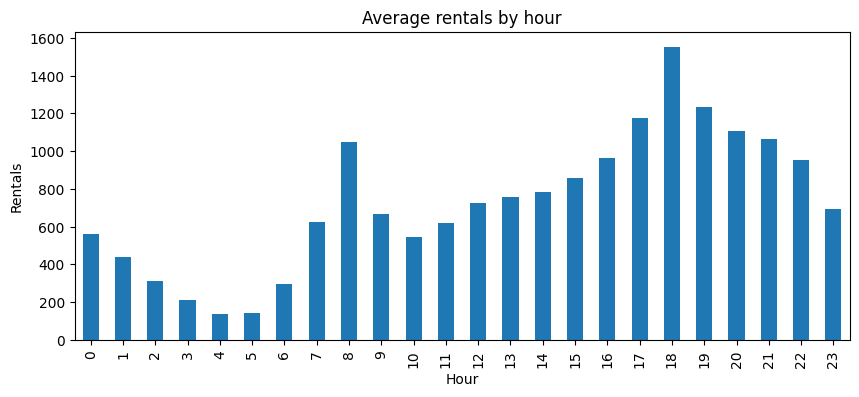

In [12]:
hour_mean = df.groupby('Hour')['Count'].mean()
hour_mean.plot(kind='bar', figsize=(10, 4))
plt.title('Average rentals by hour')
plt.xlabel('Hour')
plt.ylabel('Rentals')
plt.show()

**위 코드가 하는 일** : 시간대별 평균 대여량 그리기

**설명**
- 출근(8시)·퇴근(18시)에 튀어 오르는지 본다

**결과 해석**
- 가장 적은 때는 4시 137대, 가장 많은 때는 18시 1,554대로 약 11배 차이
- 8시(1,050대)에 한 번, 17~19시에 또 한 번 튀어 오른다 → 출퇴근 영향
- 시간과 대여량이 직선 관계가 아니라서 `Commute` 파생변수를 만들었다

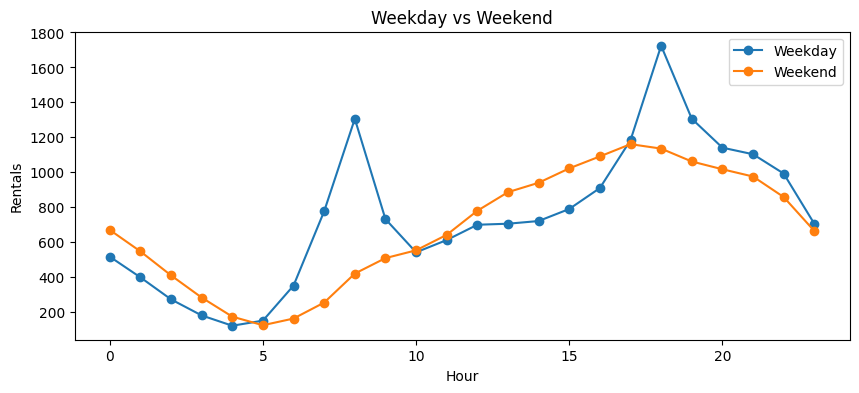

In [13]:
week = df.groupby(['Hour', 'Weekend'])['Count'].mean().unstack()
week.columns = ['Weekday', 'Weekend']
week.plot(marker='o', figsize=(10, 4))
plt.title('Weekday vs Weekend')
plt.xlabel('Hour')
plt.ylabel('Rentals')
plt.show()

**위 코드가 하는 일** : 평일과 주말의 시간대별 대여량 비교

**설명**
- `groupby` + `unstack`으로 시간 × 주말 여부 표를 만든다

**결과 해석**
- 평일 : 8시 1,306대, 18시 1,724대로 출근·퇴근 때 두 번 몰린다
- 주말 : 8시는 421대뿐이고 17시 1,161대가 가장 많다 → 출근이 없어 오후에 한 번 몰린다
- 같은 시간이라도 평일과 주말이 달라서 `Weekend` 변수를 넣었다

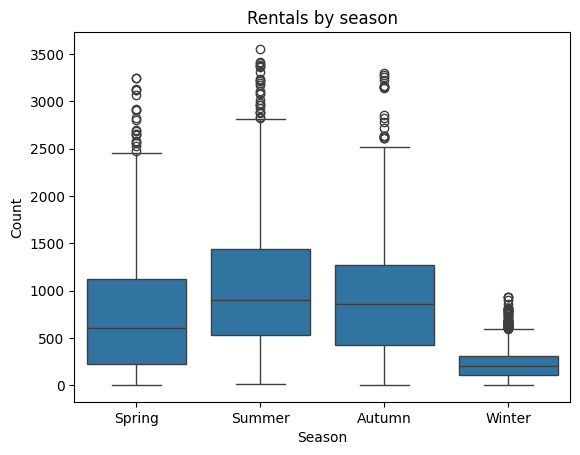

In [14]:
sns.boxplot(data=df, x='Season', y='Count')
plt.xticks([0, 1, 2, 3], ['Spring', 'Summer', 'Autumn', 'Winter'])
plt.title('Rentals by season')
plt.show()

**위 코드가 하는 일** : 계절별 대여량 분포(상자그림)

**설명**
- 가운데 선이 중앙값. 겨울에 크게 줄어드는지 본다

**결과 해석**
- 중앙값(가운데 선) : 여름 약 906대 > 가을 약 856대 > 봄 약 599대 > 겨울 약 203대
- 겨울은 상자 전체가 아래쪽에 있다 → 추우면 대여가 크게 줄어든다
- 위쪽 점들은 수요가 특히 많은 시간이다 (2장 IQR에서 본 퇴근 시간 수요)

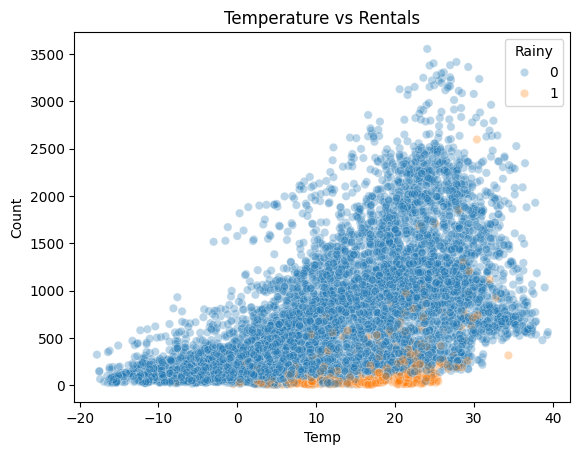

In [15]:
sns.scatterplot(data=df, x='Temp', y='Count', hue='Rainy', alpha=0.3)
plt.title('Temperature vs Rentals')
plt.show()

**위 코드가 하는 일** : 기온과 대여량 산점도

**설명**
- 색은 비 여부. 비가 오면 기온과 상관없이 낮은지 본다

**결과 해석**
- 주황(비 옴) 점은 기온과 상관없이 대부분 아래쪽에 깔려 있다 → 비가 오면 대여량이 크게 줄어든다
- 파랑(비 안 옴)은 기온이 오를수록 위로 퍼지다가, 30도를 넘으면 더 오르지 않는다
- 직선 하나로 설명하기 어려운 모양이라 선형회귀 점수가 낮게 나온다 (7장)

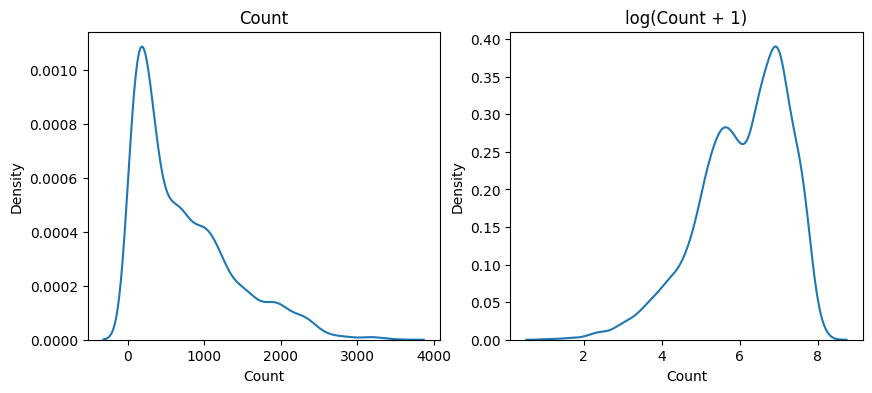

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.kdeplot(df['Count'], ax=ax[0])
ax[0].set_title('Count')
sns.kdeplot(np.log(df['Count'] + 1), ax=ax[1])
ax[1].set_title('log(Count + 1)')
plt.show()

**위 코드가 하는 일** : 대여량 분포와 로그 변환 후 분포 비교

**설명**
- 오른쪽으로 치우친 분포를 `np.log(Count + 1)`로 펴 본다 (0에는 로그를 쓸 수 없어 1을 더함)

**결과 해석**
- 왼쪽 : 0 근처에 몰리고 오른쪽으로 길게 늘어진다 (평균 705대 > 중앙값 504.5대)
- 오른쪽 : 로그를 씌우면 긴 꼬리가 줄어든다. 대신 대여가 아주 적은 새벽 쪽으로 꼬리가 생겨 완전히 고르게 되지는 않는다
- 그래서 모델의 정답은 원래 대여량(`Count`)을 그대로 쓰고, 로그 변환은 확인만 했다

## 5. 분류용 정답 만들기 (구간 나누기, 교재 11장)

In [17]:
cut1, cut2 = np.percentile(df['Count'], [33.3, 66.7])
print('기준값:', cut1, cut2)

def demand_level(count):
    if count < cut1:
        return 0      # 적음
    elif count < cut2:
        return 1      # 보통
    else:
        return 2      # 많음

df['Level'] = df['Count'].map(demand_level)
print(df['Level'].value_counts())

기준값: 285.0 896.0
Level
1    2831
2    2820
0    2814
Name: count, dtype: int64


**위 코드가 하는 일** : 대여량을 3단계(적음 / 보통 / 많음)로 나누기

**설명**
- `np.percentile`로 33.3%·66.7% 기준값을 구한다 → 세 그룹 크기가 거의 같다
- 분류 모델의 정답으로 쓴다

**결과 해석**
- 기준값 285대, 896대 → 285대 미만 적음, 896대 미만 보통, 그 이상 많음
- 세 단계가 2,814 / 2,831 / 2,820개로 거의 같다 → 한 단계로만 찍어도 맞는 쏠림이 없다 (찍으면 약 33%)

## 6. 훈련 / 검증 / 테스트 나누기 (교재 11장)

In [18]:
all_features = ['Hour', 'Temp', 'Humidity', 'Wind', 'Visibility', 'Dew', 'Solar',
                'Rain', 'Snow', 'Season', 'Holiday', 'Weekend', 'Commute', 'Rainy']
X = df[all_features]
y = df['Count']        # 회귀 정답 : 대여량
y_cls = df['Level']    # 분류 정답 : 수요 단계

X_train, X_rest, y_train, y_rest, c_train, c_rest = train_test_split(
    X, y, y_cls, test_size=0.3, random_state=42)
X_val, X_test, y_val, y_test, c_val, c_test = train_test_split(
    X_rest, y_rest, c_rest, test_size=0.5, random_state=42)

print('훈련', len(X_train), '/ 검증', len(X_val), '/ 테스트', len(X_test))

훈련 5925 / 검증 1270 / 테스트 1270


**위 코드가 하는 일** : 훈련 70% / 검증 15% / 테스트 15%로 나누기

**설명**
- 검증 = 모델 고르기용, 테스트 = 마지막에 한 번만 평가
- `train_test_split`을 두 번 쓴다 (70/30 → 30을 반반)

**결과 해석**
- 8,465행 → 훈련 5,925 / 검증 1,270 / 테스트 1,270 (70 / 15 / 15%)

## 7. 기본 모델 : 선형회귀와 로지스틱 회귀

In [19]:
feature_sets = {
    'temp':         ['Temp'],
    'weather':      ['Temp', 'Humidity', 'Wind', 'Rain', 'Snow', 'Solar'],
    'weather+time': ['Temp', 'Humidity', 'Wind', 'Rain', 'Snow', 'Solar',
                     'Hour', 'Season', 'Holiday', 'Weekend'],
    'w+t+derived':  ['Temp', 'Humidity', 'Wind', 'Rain', 'Snow', 'Solar',
                     'Hour', 'Season', 'Holiday', 'Weekend', 'Commute', 'Rainy'],
    'all':          all_features,
}

for name in feature_sets:
    cols = feature_sets[name]
    lr = LinearRegression()
    lr.fit(X_train[cols], y_train)
    pred = lr.predict(X_val[cols])
    r2 = r2_score(y_val, pred)
    rmse = np.sqrt(mean_squared_error(y_val, pred))
    print(f'{name:14s}  R2 = {r2:.3f}   RMSE = {rmse:.0f}대')

temp            R2 = 0.330   RMSE = 518대
weather         R2 = 0.437   RMSE = 475대
weather+time    R2 = 0.518   RMSE = 439대
w+t+derived     R2 = 0.601   RMSE = 400대
all             R2 = 0.603   RMSE = 399대


**위 코드가 하는 일** : 변수를 늘려 가며 선형회귀 점수 비교

**설명**
- 단순회귀 → 다중회귀 (실습 라리가 방식)
- `feature_sets` 5개는 8장 자동 탐색에서도 쓴다

**결과 해석**
- 기온 하나 0.330 → 날씨 0.437 → 시간 추가 0.518 → 파생변수 추가 0.601 : 변수를 넣을수록 좋아진다
- RMSE도 518대 → 400대로 줄었다
- 전부 쓴 `all`(0.603)은 0.601과 거의 같다 → 선형회귀로는 0.60 근처가 한계, 교수님 기준 60%를 겨우 넘는다

In [20]:
base_cols = feature_sets['w+t+derived']
lr = LinearRegression()
lr.fit(X_train[base_cols], y_train)
print(pd.Series(lr.coef_, index=base_cols).round(1))

Temp         30.8
Humidity     -6.2
Wind          3.4
Rain        -19.2
Snow          9.4
Solar       -59.1
Hour         26.6
Season      -28.6
Holiday    -133.6
Weekend     -91.1
Commute     379.5
Rainy      -494.2
dtype: float64


**위 코드가 하는 일** : 회귀계수(`coef_`) 해석 (Q2)

**설명**
- `Temp`가 +30이면 기온 1도 오를 때 약 30대 증가
- 계수는 다른 변수가 같을 때의 영향이다. 일사량처럼 기온·시간과 같이 움직이는 변수는 부호가 예상과 다를 수 있다
- 계절·시간은 숫자 크기에 의미가 없어 그대로 해석하기 어렵다

**결과 해석**
- 비 온 날 -494대, 출퇴근 +380대, 공휴일 -134대가 크게 움직인다
- 기온 +30.8 : 다른 조건이 같을 때 1도 오르면 약 31대 증가
- 일사량 -59.1은 예상과 반대 부호다 → 일사량이 기온·시간과 같이 움직여서, 그 효과를 기온·시간이 먼저 가져갔다
- 계수 크기는 단위에 따라 달라서 이것만으로 중요도를 비교하면 안 된다 → 8장에서 표준화한 계수로 비교

In [21]:
pred = lr.predict(X_val[base_cols])
print('음수로 예측한 개수 :', (pred < 0).sum(), '/', len(pred))

음수로 예측한 개수 : 118 / 1270


**위 코드가 하는 일** : 선형회귀의 한계 확인

**설명**
- 대여량은 음수가 없는데 음수를 예측한다 → 직선 관계가 아니라서. KNN·SVM이 필요한 이유

**결과 해석**
- 검증 1,270개 중 118개(약 9%)를 음수로 예측했다
- 대여량은 0 아래로 내려갈 수 없으므로 직선 모양의 선형회귀가 데이터와 맞지 않는다

In [22]:
base_scaler = StandardScaler()
Xtr_s = base_scaler.fit_transform(X_train[base_cols])
Xva_s = base_scaler.transform(X_val[base_cols])

logi = LogisticRegression(max_iter=1000)
logi.fit(Xtr_s, c_train)
print('검증 정확도 :', round(logi.score(Xva_s, c_val), 3))
print(logi.predict_proba(Xva_s[:5]).round(2))

검증 정확도 : 0.706
[[0.06 0.53 0.41]
 [0.87 0.13 0.  ]
 [0.04 0.32 0.64]
 [0.   0.07 0.93]
 [0.28 0.65 0.06]]


**위 코드가 하는 일** : 로지스틱 회귀로 3단계 분류

**설명**
- `StandardScaler`로 단위를 맞춘다 (훈련 데이터만 `fit`)
- `predict_proba` : 단계별 확률

**결과 해석**
- 검증 정확도 0.706 → 교수님 분류 기준 80%에 못 미친다
- 첫 줄 `[0.06 0.53 0.41]` : 보통 53%로 '보통'이라 예측했지만 많음 41%와 차이가 작다
- 넷째 줄 `[0. 0.07 0.93]` : 많음 93%로 확신이 크다

In [23]:
knn = KNeighborsClassifier(n_neighbors=10)
knn.fit(X_train[base_cols], c_train)
print('스케일링 전 :', round(knn.score(X_val[base_cols], c_val), 3))

knn = KNeighborsClassifier(n_neighbors=10)
knn.fit(Xtr_s, c_train)
print('스케일링 후 :', round(knn.score(Xva_s, c_val), 3))

스케일링 전 : 0.786
스케일링 후 : 0.816


**위 코드가 하는 일** : 스케일링 전·후 KNN 정확도 비교

**설명**
- KNN은 거리로 이웃을 찾아서, 숫자가 큰 변수(시정 0~2000)가 거리를 좌우한다

**결과 해석**
- 스케일링 전 0.786 → 후 0.816 (3%p 상승)
- 단위를 맞추자 시정(0~2000)처럼 숫자가 큰 변수가 거리를 독차지하지 않게 됐다 → KNN·SVM은 스케일링하고 쓴다

## 8. 최적 모델 자동 탐색 (AutoML 아이디어를 직접 구현)

수업에서 "특징을 다 쓴다고 좋아지지 않으니 **최적의 조합**을 찾으라"고 했고, 특성공학 시간에 특징을 하나씩 넣거나 빼며 점수를 보는 **특징 선택(전진·후진 탐색)**과 **스케일러 비교**를 배웠다.
교재 9장에서는 `for k in range(1, 101)`로 K를 바꿔 가며 가장 좋은 K를 찾았다. 여기서는 바꾸는 대상을 **세 가지**로 늘린다.

1. **변수 조합** : `feature_sets` 5개 (특징 선택)
2. **스케일링** : 없음 / `StandardScaler` / `MinMaxScaler`
3. **알고리즘 + 파라미터** : 선형회귀, 로지스틱 회귀(`C`), KNN(`n_neighbors`), SVM(`kernel`, `C`)

모든 조합을 학습해 **검증 점수**를 기록하고, 가장 높은 조합을 고른 뒤 **테스트 데이터로 한 번만** 최종 평가한다.
AutoML 라이브러리를 쓰지 않고 수업에서 배운 `for`문과 모델만으로 만들었다.

In [24]:
def scale_data(scaler_name, X_tr, X_ev):
    if scaler_name == 'none':
        return X_tr, X_ev, None
    if scaler_name == 'standard':
        scaler = StandardScaler()
    else:
        scaler = MinMaxScaler()
    return scaler.fit_transform(X_tr), scaler.transform(X_ev), scaler

scaler_names = ['none', 'standard', 'minmax']

# 변수 크기에 민감해서 스케일링 없이는 학습이 잘 안 되거나 매우 느린 알고리즘 → 스케일링한 경우만 탐색
needs_scaling = ['Logistic', 'SVR', 'SVC']

**위 코드가 하는 일** : 스케일링 방법을 이름으로 고르는 함수

**설명**
- `none` / `standard`(평균 0·표준편차 1) / `minmax`(0~1)
- 훈련 데이터로만 `fit`하고, 시연에서 쓰려고 scaler도 돌려준다

### 8-1. 회귀 : 대여량 예측

In [25]:
def make_regressors():
    models = []
    models.append(('Linear', LinearRegression()))
    for k in [3, 5, 7, 10, 15, 20]:
        models.append((f'KNN k={k}', KNeighborsRegressor(n_neighbors=k)))
    for c in [10, 100]:
        models.append((f'SVR rbf C={c}', SVR(kernel='rbf', C=c)))
    return models

print('회귀 후보 모델 수 :', len(make_regressors()))

회귀 후보 모델 수 : 9


**위 코드가 하는 일** : 회귀 후보 모델 목록 만들기

**설명**
- 선형회귀, KNN(k 6가지), SVR(rbf, C 2가지)
- KNN 회귀는 가까운 이웃 K개의 평균으로 예측한다
- 부를 때마다 새 모델을 만들어 결과가 섞이지 않게 한다

**결과 해석**
- 9개 = 선형회귀 1 + KNN 6 + SVR 2

In [26]:
reg_results = []

for fs_name in feature_sets:
    cols = feature_sets[fs_name]
    for sc_name in scaler_names:
        Xtr, Xva, _ = scale_data(sc_name, X_train[cols], X_val[cols])
        for m_name, model in make_regressors():
            algo = m_name.split()[0]
            if sc_name == 'none' and algo in needs_scaling:
                continue
            model.fit(Xtr, y_train)
            reg_results.append({'features': fs_name, 'scaler': sc_name,
                                'model': m_name, 'algorithm': algo,
                                'train_R2': r2_score(y_train, model.predict(Xtr)),
                                'val_R2': r2_score(y_val, model.predict(Xva))})

reg_df = pd.DataFrame(reg_results)
print(len(reg_df), '개 조합 탐색 완료')

125 개 조합 탐색 완료


**위 코드가 하는 일** : 회귀 자동 탐색

**설명**
- `for`문 3겹 : 변수 조합 × 스케일링 × 모델
- 조합마다 훈련·검증 R²를 기록한다 (1~2분 걸림)

**결과 해석**
- 변수 조합 5 × 스케일링 3 × 모델 9 = 135개 중, 스케일링 없이 쓰지 않는 SVR 10개를 빼서 125개

In [27]:
best_r = reg_df.iloc[reg_df['val_R2'].argmax()]
print(best_r)
print('훈련-검증 차이 :', round(best_r['train_R2'] - best_r['val_R2'], 3))

features     w+t+derived
scaler            minmax
model            KNN k=5
algorithm            KNN
train_R2        0.907156
val_R2          0.867598
Name: 93, dtype: object
훈련-검증 차이 : 0.04


**위 코드가 하는 일** : 검증 R² 1등 찾기

**설명**
- `argmax()` : 가장 큰 값의 위치
- 훈련·검증 R² 차이가 크면 과대적합

**결과 해석**
- 1등 : KNN k=5 + MinMax + 날씨·시간·파생변수, 검증 R² 0.868
- 훈련 0.907과 차이 0.04 → 과대적합이 크지 않다

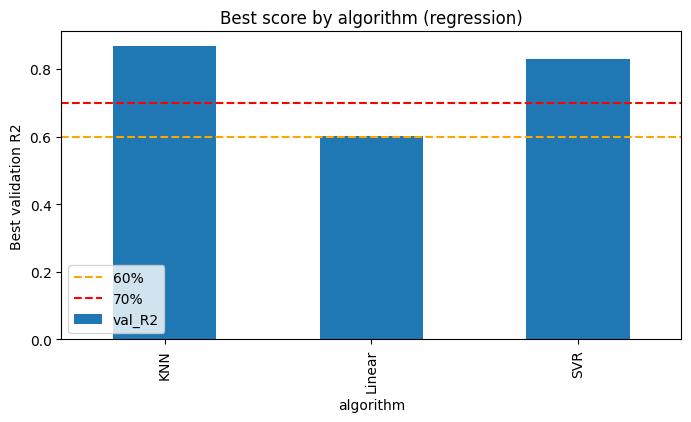

In [28]:
algo_best = reg_df.groupby('algorithm')['val_R2'].max()
algo_best.plot(kind='bar', figsize=(8, 4))
plt.axhline(0.6, color='orange', linestyle='--', label='60%')
plt.axhline(0.7, color='red', linestyle='--', label='70%')
plt.ylabel('Best validation R2')
plt.title('Best score by algorithm (regression)')
plt.legend()
plt.show()

**위 코드가 하는 일** : 알고리즘별 최고 검증 R²

**설명**
- 점선 : 60% 쓸 만함 / 70% 사용 가능 (교수님 기준)

**결과 해석**
- KNN 0.868 > SVR 0.831 > 선형회귀 0.603
- 선형회귀는 60%를 겨우 넘고, KNN·SVR은 70% 선을 넉넉히 넘는다 → 직선이 아닌 관계는 KNN·SVR이 더 잘 잡는다

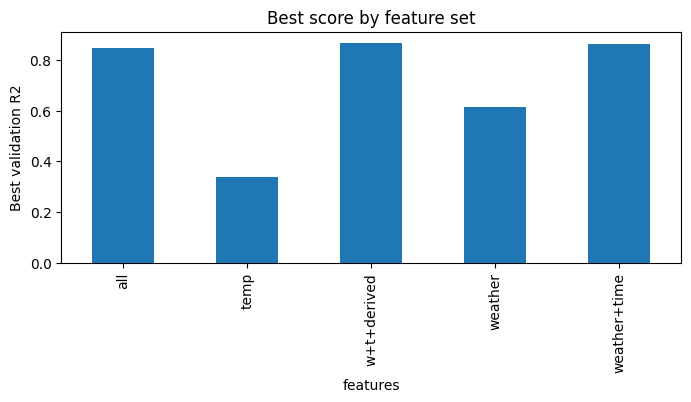

In [29]:
fs_best = reg_df.groupby('features')['val_R2'].max()
fs_best.plot(kind='bar', figsize=(8, 3))
plt.ylabel('Best validation R2')
plt.title('Best score by feature set')
plt.show()

**위 코드가 하는 일** : 변수 조합별 최고 검증 R²

**설명**
- 변수를 다 쓰는 게 항상 좋은지 확인한다

**결과 해석**
- w+t+derived 0.868 > weather+time 0.861 > all 0.848 > weather 0.612 > temp 0.338
- 전부 쓴 `all`이 1등보다 낮다 → 수업에서 말한 "특징을 다 쓴다고 정확도가 높아지지 않는다"
- 시간 변수를 넣을 때 가장 크게 오른다 (0.612 → 0.861)

In [30]:
best_cols_r = feature_sets[best_r['features']]
Xtr, Xte, best_reg_scaler = scale_data(best_r['scaler'], X_train[best_cols_r], X_test[best_cols_r])

best_reg = dict(make_regressors())[best_r['model']]
best_reg.fit(Xtr, y_train)
pred_test = best_reg.predict(Xte)

print('최적 모델 :', best_r['model'], '/', best_r['features'], '/', best_r['scaler'])
print('테스트 R2   :', round(r2_score(y_test, pred_test), 3))
print('테스트 MSE  :', round(mean_squared_error(y_test, pred_test)))
print('테스트 RMSE :', round(np.sqrt(mean_squared_error(y_test, pred_test))), '대')
print('테스트 MAE  :', round(mean_absolute_error(y_test, pred_test)), '대')

최적 모델 : KNN k=5 / w+t+derived / minmax
테스트 R2   : 0.848
테스트 MSE  : 60850
테스트 RMSE : 247 대
테스트 MAE  : 155 대


**위 코드가 하는 일** : 최적 조합을 테스트 데이터로 최종 평가

**설명**
- 탐색에 쓰지 않은 데이터로 한 번만 평가한다
- `dict(make_regressors())` : 이름으로 같은 설정의 새 모델을 꺼낸다

**결과 해석**
- R²는 클수록, MSE·RMSE·MAE는 작을수록 좋다
- RMSE·MAE는 단위가 "대"라 몇 대 틀리는지 바로 보인다
- MAPE는 대여량 0인 시간이 있어 쓰지 않는다 (0으로 나누게 됨)

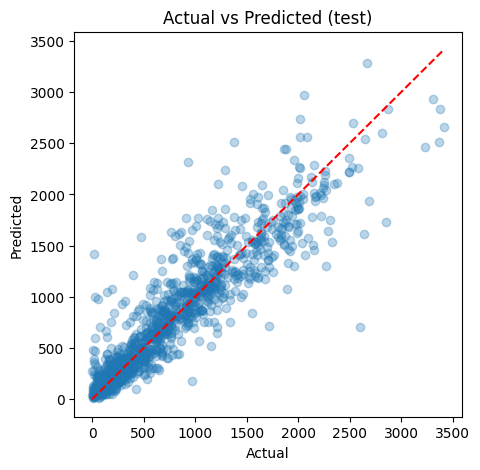

In [31]:
plt.figure(figsize=(5, 5))
plt.scatter(y_test, pred_test, alpha=0.3)
plt.plot([0, y_test.max()], [0, y_test.max()], 'r--')
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('Actual vs Predicted (test)')
plt.show()

**위 코드가 하는 일** : 예측값과 실제값 산점도

**설명**
- 빨간 점선에 가까울수록 정확. 어디서 많이 틀리는지 본다

**결과 해석**
- 대부분의 점이 빨간 점선 근처에 모여 있다 (테스트 R² 0.848)
- 오른쪽 위(실제 2,000대 이상)에서는 점이 점선 아래에 많다 → 아주 붐비는 시간은 실제보다 낮게 예측한다
- KNN은 이웃 5개의 평균을 내서 아주 큰 값이 깎이기 때문이다

Temp        370.5
Humidity   -127.5
Wind          3.5
Rain        -21.5
Snow          4.1
Solar       -51.1
Hour        183.8
Season      -32.1
Holiday     -28.9
Weekend     -41.3
Commute     165.8
Rainy      -119.7
dtype: float64


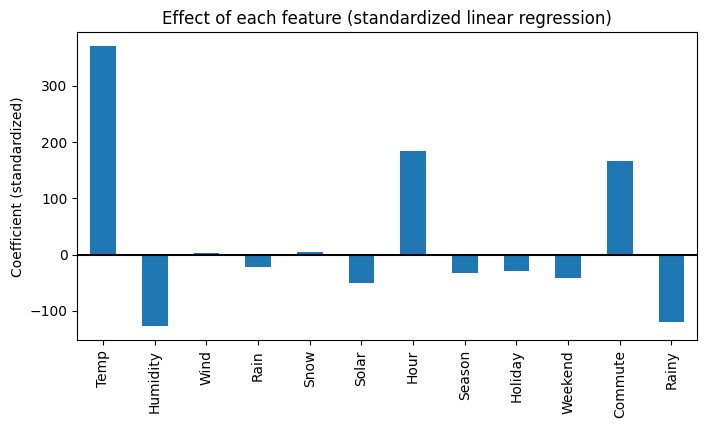

In [32]:
std_lr = LinearRegression()
std_lr.fit(base_scaler.transform(X_train[base_cols]), y_train)

effect = pd.Series(std_lr.coef_, index=base_cols)
print(effect.round(1))

effect.plot(kind='bar', figsize=(8, 4))
plt.axhline(0, color='black')
plt.ylabel('Coefficient (standardized)')
plt.title('Effect of each feature (standardized linear regression)')
plt.show()

**위 코드가 하는 일** : 표준화한 계수로 변수 영향 비교 (Q2)

**설명**
- 7장 계수는 단위가 달라 바로 비교할 수 없다 → 표준화한 뒤 비교
- 절댓값이 클수록 영향이 크다. KNN은 계수가 없어 선형회귀로 설명한다

**결과 해석**
- 기온 +371이 가장 크고, 시간 +184, 출퇴근 +166, 습도 -128, 비 온 날 -120 순이다
- 풍속(+3.5)·적설(+4.1)은 영향이 거의 없다
- 7장 계수에서는 비 온 날(-494)이 가장 커 보였지만, 단위를 맞추면 기온이 가장 중요하다

### 8-2. 분류 : 수요 단계(적음 / 보통 / 많음) 예측

In [33]:
def make_classifiers():
    models = []
    for c in [0.1, 1, 10]:
        models.append((f'Logistic C={c}', LogisticRegression(C=c, max_iter=1000)))
    for k in [3, 5, 7, 10, 15, 20]:
        models.append((f'KNN k={k}', KNeighborsClassifier(n_neighbors=k)))
    models.append(('SVC linear', SVC(kernel='linear')))
    for c in [1, 10]:
        models.append((f'SVC rbf C={c}', SVC(kernel='rbf', C=c)))
    return models

print('분류 후보 모델 수 :', len(make_classifiers()))

분류 후보 모델 수 : 12


**위 코드가 하는 일** : 분류 후보 모델 목록 만들기

**설명**
- 로지스틱(C 3가지), KNN(k 6가지), SVC(linear, rbf C 2가지)
- KNN 분류는 가까운 이웃 K개의 다수결

**결과 해석**
- 12개 = 로지스틱 3 + KNN 6 + SVC 3 (linear 1, rbf 2)

In [34]:
cls_results = []

for fs_name in feature_sets:
    cols = feature_sets[fs_name]
    for sc_name in scaler_names:
        Xtr, Xva, _ = scale_data(sc_name, X_train[cols], X_val[cols])
        for m_name, model in make_classifiers():
            algo = m_name.split()[0]
            if sc_name == 'none' and algo in needs_scaling:
                continue
            model.fit(Xtr, c_train)
            cls_results.append({'features': fs_name, 'scaler': sc_name,
                                'model': m_name, 'algorithm': algo,
                                'train_acc': accuracy_score(c_train, model.predict(Xtr)),
                                'val_acc': accuracy_score(c_val, model.predict(Xva))})

cls_df = pd.DataFrame(cls_results)
print(len(cls_df), '개 조합 탐색 완료')

best_c = cls_df.iloc[cls_df['val_acc'].argmax()]
print(best_c)

150 개 조합 탐색 완료
features      w+t+derived
scaler           standard
model        SVC rbf C=10
algorithm             SVC
train_acc        0.870886
val_acc          0.841732
Name: 107, dtype: object


**위 코드가 하는 일** : 분류 자동 탐색

**설명**
- 회귀와 같은 구조, 점수만 정확도

**결과 해석**
- 변수 조합 5 × 스케일링 3 × 모델 12 = 180개 중, 스케일링 없이 쓰지 않는 로지스틱·SVC 30개를 빼서 150개
- 1등 : SVC rbf C=10 + 표준화 + 날씨·시간·파생변수, 검증 정확도 0.842
- 훈련 0.871과 차이 0.03 → 과대적합이 크지 않다. 회귀와 같은 변수 조합이 1등

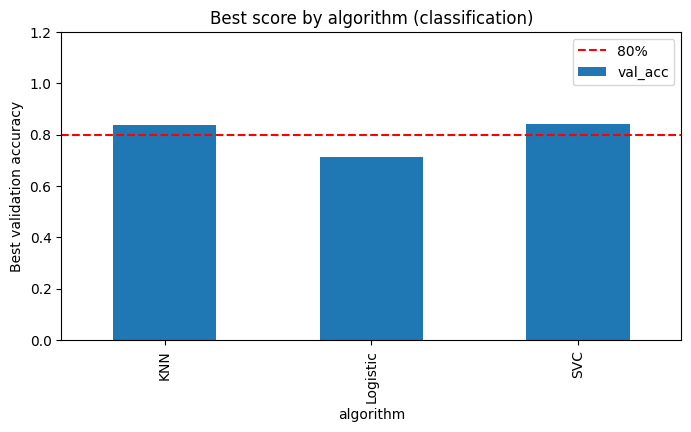

In [35]:
cls_df.groupby('algorithm')['val_acc'].max().plot(kind='bar', figsize=(8, 4))
plt.axhline(0.8, color='red', linestyle='--', label='80%')
plt.ylabel('Best validation accuracy')
plt.title('Best score by algorithm (classification)')
plt.ylim(0, 1.2)     # 위쪽에 범례 자리를 비워 둔다
plt.legend(loc='upper right')
plt.show()

**위 코드가 하는 일** : 알고리즘별 최고 검증 정확도

**설명**
- 빨간 점선 80% = 교수님 기준

**결과 해석**
- SVC 0.842 ≈ KNN 0.837 > 로지스틱 0.712
- SVC·KNN만 교수님 기준 80%를 넘는다 → 직선 경계인 로지스틱보다 곡선 경계가 맞는 데이터다

In [36]:
best_cols_c = feature_sets[best_c['features']]
Xtr, Xte, best_cls_scaler = scale_data(best_c['scaler'], X_train[best_cols_c], X_test[best_cols_c])

best_cls = dict(make_classifiers())[best_c['model']]
best_cls.fit(Xtr, c_train)
pred_c = best_cls.predict(Xte)

print('최적 모델 :', best_c['model'], '/', best_c['features'], '/', best_c['scaler'])
print('정확도 :', round(accuracy_score(c_test, pred_c), 3))
print('정밀도 :', round(precision_score(c_test, pred_c, average='macro'), 3))
print('재현율 :', round(recall_score(c_test, pred_c, average='macro'), 3))
print('F1     :', round(f1_score(c_test, pred_c, average='macro'), 3))

최적 모델 : SVC rbf C=10 / w+t+derived / standard
정확도 : 0.824
정밀도 : 0.823
재현율 : 0.823
F1     : 0.823


**위 코드가 하는 일** : 최적 분류 모델을 테스트 데이터로 평가

**설명**
- 정밀도 : "많음"이라 예측한 것 중 실제로 많았던 비율
- 재현율 : 실제로 많았던 것 중 맞힌 비율
- F1 : 둘의 조화평균 / `macro` : 3단계 점수의 단순 평균

**결과 해석**
- 테스트 정확도 0.824로 검증 0.842와 비슷하다 → 처음 보는 데이터에서도 성능이 유지된다
- 정밀도·재현율·F1이 모두 0.823 → 한 단계만 잘 맞히지 않고 세 단계를 고르게 맞힌다

       예측 적음  예측 보통  예측 많음
실제 적음    355     69      3
실제 보통     60    301     52
실제 많음      0     39    391


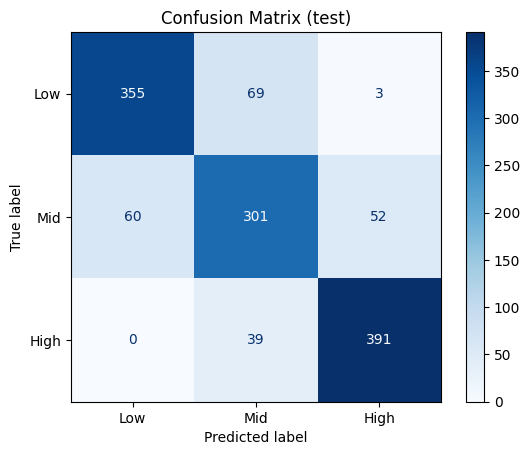

In [37]:
cm = confusion_matrix(c_test, pred_c)
print(pd.DataFrame(cm, index=['실제 적음', '실제 보통', '실제 많음'],
                   columns=['예측 적음', '예측 보통', '예측 많음']))

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Low', 'Mid', 'High'])
disp.plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix (test)')
plt.show()

**위 코드가 하는 일** : 혼동행렬 그리기

**설명**
- 행 = 실제, 열 = 예측, 대각선이 맞힌 개수
- 0 = 적음(Low), 1 = 보통(Mid), 2 = 많음(High)

**결과 해석**
- 대각선(맞힌 개수) 355 + 301 + 391 = 1,047개 / 전체 1,270개 → 정확도 0.824
- '적음'을 '많음'으로 본 경우 3개, '많음'을 '적음'으로 본 경우 0개 → 틀려도 대부분 바로 옆 단계와 헷갈린 것
- '보통'을 가장 많이 헷갈린다 : 실제 보통 413개 중 301개만 맞힘(재현율 0.73). 적음과 많음 사이라 경계가 애매하다
- '많음'은 430개 중 391개 맞힘(재현율 0.91), '적음'은 0.83 → 자전거를 옮겨야 하는 붐비는 시간은 잘 잡아낸다

## 9. 시연 : 조건을 넣으면 대여량 예측

In [38]:
def make_row(hour, temp, humidity, wind, rain, snow, season, holiday, weekday, solar=0.0):
    row = {'Hour': hour, 'Temp': temp, 'Humidity': humidity, 'Wind': wind,
           'Visibility': 2000,
           'Dew': temp - (100 - humidity) / 5,     # 이슬점 근사식
           'Solar': solar, 'Rain': rain, 'Snow': snow,
           'Season': season, 'Holiday': holiday,
           'Weekend': 1 if weekday >= 5 else 0,
           'Commute': commute.get(hour, 0),
           'Rainy': 1 if rain > 0 else 0}
    return pd.DataFrame([row])

**위 코드가 하는 일** : 입력 조건을 한 줄짜리 표로 만들기

**설명**
- 주말·출퇴근·비 여부는 3장 규칙으로 자동 계산
- 이슬점은 근사식, 시정은 맑은 날 값(2000)

In [39]:
level_names = ['적음', '보통', '많음']

def predict_demand(hour, temp, humidity, wind, rain, snow, season, holiday, weekday, solar=0.0):
    row = make_row(hour, temp, humidity, wind, rain, snow, season, holiday, weekday, solar)

    Xr = row[best_cols_r]
    if best_reg_scaler is not None:
        Xr = best_reg_scaler.transform(Xr)
    count = best_reg.predict(Xr)[0]

    Xc = row[best_cols_c]
    if best_cls_scaler is not None:
        Xc = best_cls_scaler.transform(Xc)
    level = best_cls.predict(Xc)[0]

    proba = logi.predict_proba(base_scaler.transform(row[base_cols]))[0]

    print(f'예상 대여량 : {max(count, 0):.0f}대')
    print(f'수요 단계   : {level_names[level]}')
    print(f'단계별 확률(로지스틱 회귀) : 적음 {proba[0]:.0%} / 보통 {proba[1]:.0%} / 많음 {proba[2]:.0%}')

**위 코드가 하는 일** : 조건을 넣으면 예측하는 함수

**설명**
- 대여량 = 최적 회귀 모델 (음수면 0) / 단계 = 최적 분류 모델
- 확률은 로지스틱 회귀 `predict_proba` → 다른 모델이라 단계와 다를 수 있다
- 학습 때와 같은 scaler로 바꿔서 넣는다

In [40]:
print('① 여름 평일 퇴근길 (18시, 25도, 맑음)')
predict_demand(hour=18, temp=25, humidity=50, wind=2.0, rain=0, snow=0,
               season=1, holiday=0, weekday=2, solar=0.5)

print('\n② 겨울 주말 새벽 (5시, -8도)')
predict_demand(hour=5, temp=-8, humidity=40, wind=1.5, rain=0, snow=0,
               season=3, holiday=0, weekday=6)

print('\n③ 가을 평일 출근길에 비 (8시, 15도, 비 5mm)')
predict_demand(hour=8, temp=15, humidity=90, wind=3.0, rain=5, snow=0,
               season=2, holiday=0, weekday=1, solar=0.1)

① 여름 평일 퇴근길 (18시, 25도, 맑음)
예상 대여량 : 2743대
수요 단계   : 많음
단계별 확률(로지스틱 회귀) : 적음 0% / 보통 5% / 많음 95%

② 겨울 주말 새벽 (5시, -8도)
예상 대여량 : 37대
수요 단계   : 적음
단계별 확률(로지스틱 회귀) : 적음 94% / 보통 6% / 많음 0%

③ 가을 평일 출근길에 비 (8시, 15도, 비 5mm)
예상 대여량 : 138대
수요 단계   : 적음
단계별 확률(로지스틱 회귀) : 적음 88% / 보통 11% / 많음 0%


**위 코드가 하는 일** : 세 가지 상황 넣어 보기

**설명**
- 계절 : 봄 0 ~ 겨울 3 / 요일 : 월 0 ~ 일 6

**결과 해석**
- ① 여름 퇴근길 2,743대, 많음 95% → 4장 그래프의 평일 18시 피크와 맞는다
- ② 겨울 주말 새벽 37대 → 시간대 그래프의 새벽 최저(4시 137대)보다도 낮다. 겨울·영하라 더 줄었다
- ③ 출근 시간인데도 비가 와서 138대 → 비가 출퇴근 효과를 거의 없앤다 (7장 계수 : 비 온 날 -494대)
- 대여량은 KNN, 단계는 SVC, 확률은 로지스틱 회귀가 낸 값이다

## 10. 결론

### Q1. 따릉이는 언제 가장 많이 탈까?
- 퇴근 시간(18시)이 평균 1,554대로 가장 많고, 새벽 4시가 137대로 가장 적다. 출근 시간(8시)에도 1,050대로 한 번 튀어 오른다
- 평일은 출근(8시 1,306대)과 퇴근(18시 1,724대)에 두 번 높아진다. 주말은 오후(17시 1,161대)에 한 번만 높아진다 → 평일은 출퇴근용, 주말은 여가용으로 많이 탄다
- 계절은 여름(1,034대) > 가을(924대) > 봄(746대) > 겨울(226대) 순이다. 겨울은 여름의 약 1/5 수준이다

### Q2. 날씨 중 무엇이 가장 큰 영향을 줄까?
- 변수를 표준화하고 선형회귀 계수를 비교했다. 기온(+371) > 시간(+184) > 출퇴근 여부(+166) > 습도(-128) > 비 여부(-120) 순으로 영향이 컸다
- 날씨만 보면 **기온**이 가장 크고, 그다음이 습도와 비다
- 표준화 전 계수로 보면 기온이 1도 오를 때 약 31대 늘고, 비가 오는 시간에는 약 494대 줄어든다. 실제 평균도 비가 안 올 때 766대, 비가 올 때 167대로 크게 차이 난다
- 출퇴근 시간 여부(+380대)와 비 여부(-494대)는 우리가 직접 만든 파생변수다. 이 둘을 넣자 선형회귀 검증 R²가 0.518에서 0.601로 올랐다

### Q3. 얼마나 정확히 예측할 수 있을까?
| 단계 | 모델 | 점수 | 교수님 기준 |
|---|---|---|---|
| 기온만 사용 | 선형회귀 | 검증 R² 0.330 | 미달 |
| 파생변수까지 사용 | 선형회귀 | 검증 R² 0.601 | 60%를 겨우 넘음 |
| **자동 탐색 (125개 조합)** | KNN (k=5, MinMax) | **테스트 R² 0.848**, RMSE 247대, MAE 155대 | 70~80% 달성 |
| **자동 탐색 (150개 조합)** | SVM (SVC rbf, C=10, 표준화) | **테스트 정확도 0.824**, F1 0.823 | 80% 달성 |

- 선형회귀는 기준에 겨우 걸렸다. 변수 조합·스케일링·알고리즘을 자동 탐색해서 R²를 0.60에서 0.85로 올렸다
- 변수를 전부 쓴 조합(검증 R² 0.848)보다 날씨 + 시간 + 파생변수 조합(0.868)이 더 좋았다 → 수업에서 배운 "특징을 다 쓴다고 정확도가 높아지는 것은 아니다"를 직접 확인했다
- 분류에서 '적음'을 '많음'으로(또는 반대로) 완전히 틀린 경우는 1,270건 중 3건뿐이고, 대부분의 오류는 바로 옆 단계('보통')와 헷갈린 것이다

### 한계
- 대여량이 아주 많은 시간대(2,500대 이상)는 예측이 실제보다 낮게 나오는 경향이 있다
- 데이터를 무작위로 나눴기 때문에 같은 날의 다른 시간대가 훈련 데이터에 들어 있다. 또 1년치 데이터라서 학습하지 않은 계절이나 다음 해는 정확도가 떨어질 수 있다 → 여러 해 데이터로 시간순 검증이 필요하다
- 대여소 위치, 행사, 미세먼지처럼 데이터에 없는 요인은 반영하지 못했다
- 자동 탐색의 후보(알고리즘 4종, 파라미터 몇 가지)는 우리가 정한 범위 안에서만 찾은 것이다

### 활용 제안
- **자전거 재배치** : 평일 17~19시 수요가 가장 크므로, 그 전에 업무 지구 대여소에 자전거를 채워 둔다
- **정비 일정** : 수요가 가장 적은 새벽 3~5시, 비 예보가 있는 날, 겨울철에 정비·점검을 몰아서 한다
- **수요 예보** : 기상 예보(기온·강수)를 넣으면 다음 날 시간대별 예상 대여량을 미리 볼 수 있다

## 11. 생성형 AI 활용 기록

**AI는 초안을 만드는 도구로 썼고, 무엇을 할지와 결과가 맞는지는 우리가 정하고 확인했다.**
- 방향 : 수업에서 배운 것만 쓰고, 실습 방식(`map`, `to_datetime`, KNN 스케일링 비교)을 따르기로 우리가 정했다
- 검증 : 노트북을 코랩에서 직접 실행했고, 실습 노트북과 대조해 실습에 없는 함수 5개를 바꿨다
- 수정 : 옛 결과 숫자가 남은 발표 자료, 잘린 주석, 음성과 화면이 어긋난 장면을 직접 찾아 고치게 했다
- 해석 : 그래프·출력마다 결과 해석이 있어야 한다고 판단해 추가했고, 숫자를 출력과 대조했다

| 단계 | 사용 도구 | 입력한 프롬프트 (원문) | AI 결과 | 우리가 검증·수정한 것 |
|---|---|---|---|---|
| 가능성 확인 | Claude | "지금 우리가 배우는걸로 automl이 가능해?" | AutoML 라이브러리 대신 `for`문으로 직접 탐색하는 방법 제안 | 라이브러리는 수업 범위 밖이라 쓰지 않기로 함 |
| 주제 선정 | Claude | "근데 우리가 배운 범위 안에서 해야하거든. 평가방법까진 진도 나간다고 했으니 그거 포함해서 주제 추천해줘." | 따릉이 수요 예측 + 자동 탐색 추천 | 데이터를 직접 열어 결측치·인코딩 확인 |
| 방식 지정 | Claude | "근데 우리가 실습한 내용도 썼으면 하거든 완전히 똑같이 쓰라는게 아니고 방식 같은걸 말하는거야" | 실습 방식(라리가 `map`, 슈퍼마켓 `to_datetime`, wine KNN 등)을 따릉이에 맞게 적용 | 실습 노트북과 비교해 방식이 맞는지 확인 |
| 노트북 뼈대 | Claude | "그럼 코랩 노트북 뼈대 만들어줘" | 노트북 초안 | 코랩에서 직접 실행해 오류와 결과 확인 |
| 범위 검증 | Claude | "그런데 우리가 배운 범위안에서만 하는거 맞아?" | 실습에 없는 함수 5개 발견 | `heatmap`, `corr`, `sort_values`, `quantile`, `hasattr`를 실습 함수로 교체 |
| 결과 검증 | Claude | "방금 만든 ipyb 파일" (검증 명령과 함께 입력) | 실행 결과와 설명 대조 | 실제 결과와 다른 설명 3곳 수정 |
| 코드 검토 | ChatGPT | "따릉이수요예측 코드에는 고칠점 있을까? 검토 해줘" | 원본 CSV로 코드 셀을 실행하며 고칠 점 검토 | 모델 점수·시연 출력이 코랩 결과와 같은지 확인 |
| 결론 | Claude | "10장 결론 초안 써줘" | 실행 결과 숫자로 결론 초안 | 숫자를 코랩 결과와 다시 대조 |
| 결과 해석 | Claude | "그래프가 나오거나 값이 나오는 부분은 해석이나 설명이 있는게 더 좋을거 같거든" | 출력 셀 33곳의 해석 초안 | 해석이 필요하다고 우리가 판단, 숫자를 출력·그래프와 대조 |
| 발표 영상 | Claude | "근데 그냥 자막만 하면 보기 귀찮기도 하니깐 자막이랑 TTS 둘다 넣는 형식으로 가자" | 슬라이드·음성·자막 초안, 영상 합치기 | 목소리를 직접 듣고 골랐고, 옛 숫자가 남은 PPT·잘린 주석·음성과 안 맞는 장면을 찾아 고치게 함 |